# Logistic Regression Project: Diabetes Prediction using Kaggle Data
**Student:** Gangadhar Kalse  
**Batch:** SEP(B)  
**Dataset:** Pima Indians Diabetes Database (Kaggle) - `diabetes.csv`  
**Objective:** Predict `Outcome` (0 = No diabetes, 1 = Diabetes)  
**Model:** Median imputation + StandardScaler + balanced Logistic Regression

**Workflow:** load Kaggle CSV → inspect data → replace invalid zeros → train-test split → median imputation → scaling → train Logistic Regression → evaluate → interpret coefficients

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("Student : Gangadhar Kalse")
print("Batch   : SEP(B)")

Student : Gangadhar Kalse
Batch   : SEP(B)


## 2. Load the Kaggle CSV

In [2]:
df = pd.read_csv("diabetes.csv")
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Inspect the Data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [5]:
print("Missing values (NaN) per column:\n", df.isnull().sum())
print("\nClass distribution (Outcome):")
print(df["Outcome"].value_counts())
print("\nClass percentage:")
print((df["Outcome"].value_counts(normalize=True) * 100).round(2))

Missing values (NaN) per column:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Class distribution (Outcome):
Outcome
0    500
1    268
Name: count, dtype: int64

Class percentage:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


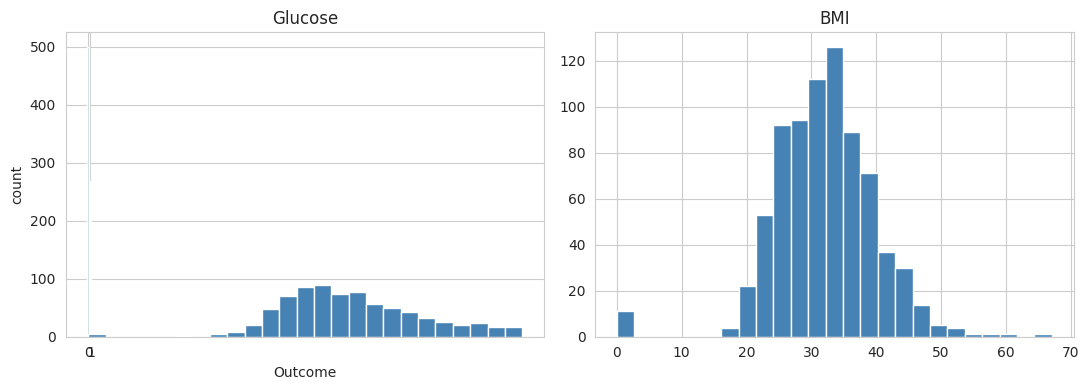

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Outcome", data=df, palette="Blues", ax=ax[0])
ax[0].set_title("Outcome Distribution (0 = No diabetes, 1 = Diabetes)")
df.hist(column=["Glucose", "BMI"], bins=25, ax=ax, color="steelblue")
plt.tight_layout(); plt.show()

## 4. Replace Invalid Zeros
A value of 0 is biologically impossible for Glucose, BloodPressure, SkinThickness, Insulin and BMI. These zeros actually represent missing readings, so they are replaced with `NaN` (they will be filled by median imputation after the split).

In [7]:
zero_invalid_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zeros before replacement:")
print((df[zero_invalid_cols] == 0).sum())

df[zero_invalid_cols] = df[zero_invalid_cols].replace(0, np.nan)

print("\nMissing values after replacement:")
print(df.isnull().sum())

Zeros before replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values after replacement:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


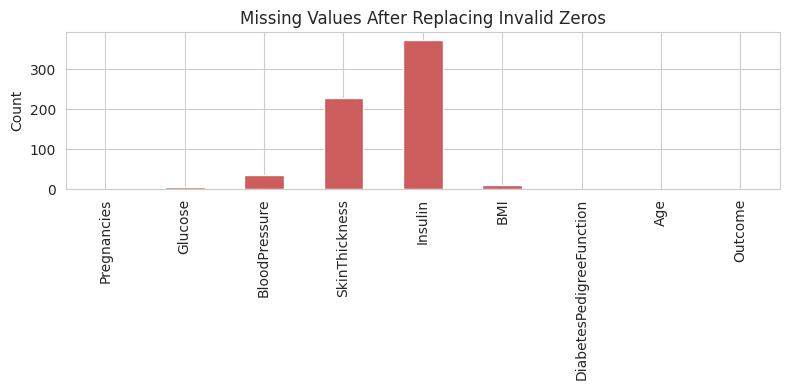

In [8]:
plt.figure(figsize=(8, 4))
df.isnull().sum().plot(kind="bar", color="indianred")
plt.title("Missing Values After Replacing Invalid Zeros"); plt.ylabel("Count")
plt.tight_layout(); plt.show()

## 5. Train-Test Split
Stratified 80/20 split with a fixed `random_state` so results are reproducible. The split is done **before** imputation and scaling to avoid data leakage.

In [9]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("Train size:", X_train.shape, "| Test size:", X_test.shape)
print("Train class %:", (y_train.value_counts(normalize=True)*100).round(1).to_dict())
print("Test class %:",  (y_test.value_counts(normalize=True)*100).round(1).to_dict())

Train size: (614, 8) | Test size: (154, 8)
Train class %: {0: 65.1, 1: 34.9}
Test class %: {0: 64.9, 1: 35.1}


## 6. Median Imputation → Scaling → Logistic Regression (Pipeline)
`class_weight='balanced'` gives more weight to the minority (diabetes) class so that recall for positive cases improves.

In [10]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
    ("clf",     LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
print("Model trained successfully")
print("Median values learned by imputer (from training data only):")
print(pd.Series(model.named_steps["imputer"].statistics_, index=X.columns).round(2))

Model trained successfully
Median values learned by imputer (from training data only):
Pregnancies                   3.00
Glucose                     117.00
BloodPressure                72.00
SkinThickness                29.00
Insulin                     125.00
BMI                          32.40
DiabetesPedigreeFunction      0.38
Age                          29.00
dtype: float64


## 7. Evaluate the Model

In [11]:
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Result": [accuracy_score(y_test, y_pred),
               precision_score(y_test, y_pred),
               recall_score(y_test, y_pred),
               f1_score(y_test, y_pred),
               roc_auc_score(y_test, y_proba)],
    "Meaning": ["Overall correct predictions",
                "Reliability of positive predictions",
                "Actual positive cases detected",
                "Balance of precision and recall",
                "Overall class-separation ability"]
})
metrics["Result"] = metrics["Result"].round(3)
metrics

,Metric,Result,Meaning
0,Accuracy,0.734,Overall correct predictions
1,Precision,0.603,Reliability of positive predictions
2,Recall,0.704,Actual positive cases detected
3,F1-score,0.650,Balance of precision and recall
4,ROC-AUC,0.813,Overall class-separation ability


In [12]:
print(classification_report(y_test, y_pred, target_names=["No diabetes (0)", "Diabetes (1)"]))

                 precision    recall  f1-score   support

No diabetes (0)       0.82      0.75      0.79       100
   Diabetes (1)       0.60      0.70      0.65        54

       accuracy                           0.73       154
      macro avg       0.71      0.73      0.72       154
   weighted avg       0.75      0.73      0.74       154



### Confusion Matrix

TN = 75 | FP = 25
FN = 16 | TP = 38


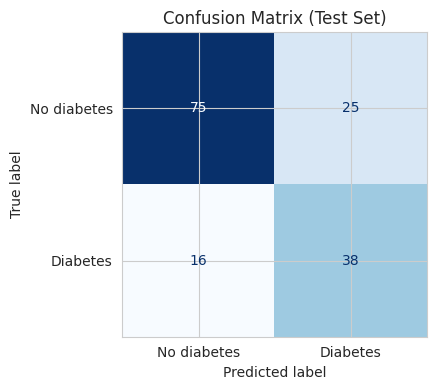

In [13]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp}\nFN = {fn} | TP = {tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(
    cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix (Test Set)")
plt.tight_layout(); plt.show()

### ROC Curve

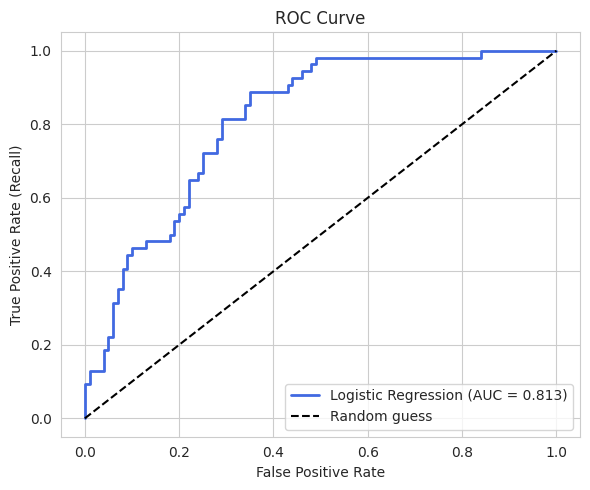

In [14]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="royalblue", lw=2, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8. Interpret the Coefficients
Because features are standardized, coefficients are directly comparable. A larger positive coefficient means a stronger increase in the log-odds of diabetes.

In [15]:
coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.named_steps["clf"].coef_[0],
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)
coef["Odds Ratio (per +1 SD)"] = np.exp(coef["Coefficient"]).round(3)
coef["Coefficient"] = coef["Coefficient"].round(3)
coef

,Feature,Coefficient,Odds Ratio (per +1 SD)
0,Glucose,1.183,3.266
1,BMI,0.710,2.033
2,Pregnancies,0.373,1.452
3,DiabetesPedigreeFunction,0.288,1.333
4,Age,0.186,1.205
5,SkinThickness,0.014,1.014
6,BloodPressure,-0.015,0.985
7,Insulin,-0.045,0.956


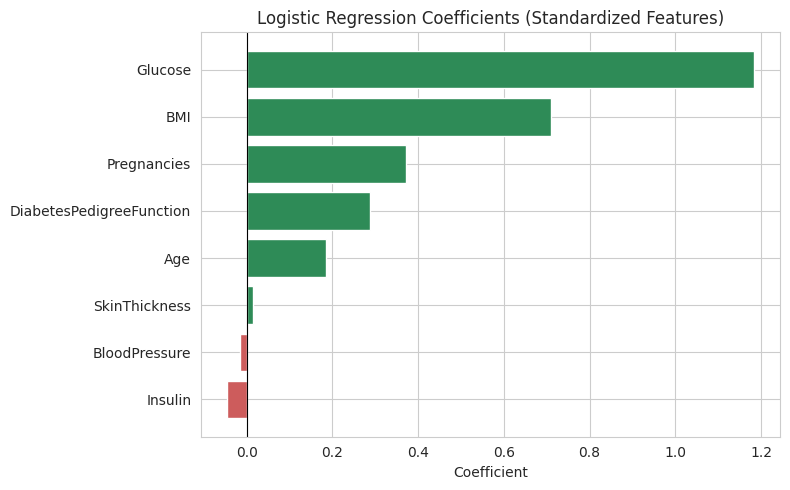

Top two positive predictors: ['Glucose', 'BMI']


In [16]:
plt.figure(figsize=(8, 5))
colors = ["seagreen" if c > 0 else "indianred" for c in coef["Coefficient"]]
plt.barh(coef["Feature"][::-1], coef["Coefficient"][::-1], color=colors[::-1])
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic Regression Coefficients (Standardized Features)")
plt.xlabel("Coefficient")
plt.tight_layout(); plt.show()
print("Top two positive predictors:", list(coef["Feature"][:2]))

## 9. Key Findings and Conclusion

In [17]:
print(f"ROC-AUC  : {auc:.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}  -> {recall_score(y_test, y_pred)*100:.1f}% of actual diabetes cases detected")
print(f"Missed positive cases (FN): {fn} out of {fn+tp}")
print(f"False alarms (FP)         : {fp} out of {fp+tn}")

ROC-AUC  : 0.813
Recall   : 0.704  -> 70.4% of actual diabetes cases detected
Missed positive cases (FN): 16 out of 54
False alarms (FP)         : 25 out of 100


**Conclusion (Gangadhar Kalse, SEP(B))**

I built a Logistic Regression model on the Pima Indians Diabetes data. Zeros that were impossible in Glucose, BloodPressure, SkinThickness, Insulin and BMI were treated as missing and filled with the training median. After scaling the features, the balanced model reached a ROC-AUC of about 0.813 and recall of 0.704, meaning it detects around 70% of real diabetes cases in the test set. Glucose and BMI have the strongest positive coefficients, so higher values of these raise the predicted risk of diabetes the most.

Recall matters most in a screening-style task because a false negative is a missed patient. The price of the high recall is a lower precision (0.603), so there are some false alarms. 

**Limitation:** The dataset is small and comes from one specific population, so the model is meant for learning classification concepts and must not be used for real medical diagnosis.